# Benchmarking for tridiagonal solvers

This notebook evaluates the time and memory costs of the tridiagonal solvers $\verb|Thomas algorithm|$, $\verb|Parallel cyclic reduction|$ and the dense solver $\verb|torch.linalg.solve|$ for various system dimensions and batch sizes.

Since the computations for benchmarking can be extensive, this notebook plots pre-computed results. Therefore, <mark>please generate the benchmarking results beforehand</mark> using the scripts $\verb|benchmarks.sh|$ and $\verb|benchmakrs.py|$ and modify the path below, if necessary.

In [ ]:
import torch
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm, Normalize
import numpy as np

import pickle

In [ ]:
n_rows_all = [16, 32, 64, 128, 256]
n_batch_all = [2**i for i in range(0, 14, 2)]

# load times, memory costs from file

In [ ]:
n_rows_all = [16, 32, 64, 128, 256]
n_batch_all = [2**i for i in range(0, 28, 1)]

load_path = '/gpfs/work/nimtz/experiments/benchmark_tridiagonal/'

f_solver = 'tridiagonal_solve'
method='thomas'
implicit_backward = True
requires_grad = False
use_cuda = True

In [ ]:
methods = ("thomas", "paracr", "linalg")
implicit_backwards = (True, False)
use_cudas = (True, False)
f_solvers_requires_grads = (('tridiagonal_solve', False, 'nograd'), ('tridiagonal_solve', True, 'grad'), ('tridiagonal_sum_backward', True, 'fb'))

for _m in methods:
    for _ib in implicit_backwards:
        for _c in use_cudas:
            for _s, _g, _mode in f_solvers_requires_grads:
                try:
                    with open(load_path+f'{_s}_{_m}_{"implicit" if _ib else "explicit"}_{"grad" if _g else "nograd"}_{"cuda" if _c else "cpu"}.pkl', 'rb') as file:
                                t = pickle.load(file)
                                m = pickle.load(file)
                                print(m.shape)
                    print('found', load_path+f'{_s}_{_m}_{"implicit" if _ib else "explicit"}_{"grad" if _g else "nograd"}_{"cuda" if _c else "cpu"}.pkl')
                    _name = f'_{_mode}_{"im" if _ib else "ex"}_{_m}{"" if _c else "_cpu"}'
                    globals()['t'+_name], globals()['m'+_name] = t, m
                except FileNotFoundError:
                    print(load_path+f'{_s}_{_m}_{"implicit" if _ib else "explicit"}_{"grad" if _g else "nograd"}_{"cuda" if _c else "cpu"}.pkl', 'does not exist')
                    None
            _n = f'_{"im" if _ib else "ex"}_{_m}{"" if _c else "_cpu"}'
            try:
                globals()['t_back'+_n] = eval('t_fb'+_n)# - eval('t_grad'+_n)
                globals()['m_back'+_n] = eval('m_fb'+_n) - eval('m_grad'+_n)
            except NameError:
                None

torch.Size([5, 28])
found /gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_solve_thomas_implicit_nograd_cuda.pkl
torch.Size([5, 28])
found /gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_solve_thomas_implicit_grad_cuda.pkl
torch.Size([5, 28])
found /gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_sum_backward_thomas_implicit_grad_cuda.pkl
/gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_solve_thomas_implicit_nograd_cpu.pkl does not exist
/gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_solve_thomas_implicit_grad_cpu.pkl does not exist
/gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_sum_backward_thomas_implicit_grad_cpu.pkl does not exist
torch.Size([5, 28])
found /gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_solve_thomas_explicit_nograd_cuda.pkl
torch.Size([5, 28])
found /gpfs/work/nimtz/experiments/benchmark_tridiagonal/tridiagonal_solve_thomas_explicit_grad_cuda.pkl
torch.Size([5, 2

# Plot benchmarking

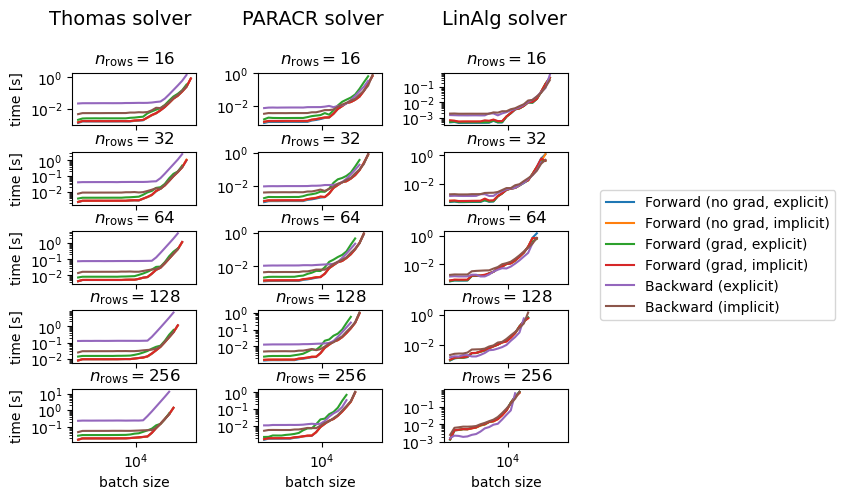

In [ ]:
f, ax = plt.subplots(len(n_rows_all), 3, sharex=True)
for i, n_rows in enumerate(n_rows_all):
    ax[i, 0].plot(n_batch_all, t_nograd_ex_thomas[i,:], label='Forward (no grad, explicit)')
    ax[i, 0].plot(n_batch_all, t_nograd_im_thomas[i,:], label='Forward (no grad, implicit)')
    ax[i, 0].plot(n_batch_all, t_grad_ex_thomas[i,:], label='Forward (grad, explicit)')
    ax[i, 0].plot(n_batch_all, t_grad_im_thomas[i,:], label='Forward (grad, implicit)')
    ax[i, 0].plot(n_batch_all, t_back_ex_thomas[i,:], label='Backward (explicit)')
    ax[i, 0].plot(n_batch_all, t_back_im_thomas[i,:], label='Backward (implicit)')
    tstr = f'$n_\\text{{rows}} = {n_rows}$'
    ax[i, 0].set_title(tstr)
    ax[i, 0].set_ylabel('time [s]')
    # if i == 0:
    #     ax[i, 0].legend()
ax[-1, 0].set_xlabel('batch size')
for i, n_rows in enumerate(n_rows_all):
    ax[i, 1].plot(n_batch_all, t_nograd_ex_paracr[i,:], label='Forward (no grad, explicit)')
    ax[i, 1].plot(n_batch_all, t_nograd_im_paracr[i,:], label='Forward (no grad, implicit)')
    ax[i, 1].plot(n_batch_all, t_grad_ex_paracr[i,:], label='Forward (grad, explicit)')
    ax[i, 1].plot(n_batch_all, t_grad_im_paracr[i,:], label='Forward (grad, implicit)')
    ax[i, 1].plot(n_batch_all, t_back_ex_paracr[i,:], label='Backward (explicit)')
    ax[i, 1].plot(n_batch_all, t_back_im_paracr[i,:], label='Backward (implicit)')
    tstr = f'$n_\\text{{rows}} = {n_rows}$'
    ax[i, 1].set_title(tstr)
    # ax[i, 1].set_ylabel('time [s]')
ax[-1, 1].set_xlabel('batch size')
for i, n_rows in enumerate(n_rows_all):
    ax[i, 2].plot(n_batch_all, t_nograd_ex_linalg[i,:], label='Forward (no grad, explicit)')
    ax[i, 2].plot(n_batch_all, t_nograd_im_linalg[i,:], label='Forward (no grad, implicit)')
    ax[i, 2].plot(n_batch_all, t_grad_ex_linalg[i,:], label='Forward (grad, explicit)')
    ax[i, 2].plot(n_batch_all, t_grad_im_linalg[i,:], label='Forward (grad, implicit)')
    ax[i, 2].plot(n_batch_all, t_back_ex_linalg[i,:], label='Backward (explicit)')
    ax[i, 2].plot(n_batch_all, t_back_im_linalg[i,:], label='Backward (implicit)')
    tstr = f'$n_\\text{{rows}} = {n_rows}$'
    ax[i, 2].set_title(tstr)
    # ax[i, 2].set_ylabel('time [s]')
ax[-1, 2].set_xlabel('batch size')

f.text(0.2, 0.98, "Thomas solver", ha="center", fontsize=14)
f.text(0.5, 0.98, "PARACR solver", ha="center", fontsize=14)
f.text(0.8, 0.98, "LinAlg solver", ha="center", fontsize=14)

handles, labels = ax[0, 0].get_legend_handles_labels()

for _ax in ax.flat:
    _ax.set_xscale('log')
    _ax.set_yscale('log')

f.legend(
    handles, labels,
    loc="center left",
    bbox_to_anchor=(0.95, 0.5),
    borderaxespad=0,
)
f.subplots_adjust(hspace=0.5, wspace=0.5); plt.show()

tensor(0.0013, dtype=torch.float64) tensor(0.0014, dtype=torch.float64) tensor(0.0020, dtype=torch.float64) tensor(0.0014, dtype=torch.float64) tensor(0.0219, dtype=torch.float64) tensor(0.0046, dtype=torch.float64) tensor(0.0009, dtype=torch.float64) tensor(0.0010, dtype=torch.float64) tensor(0.0015, dtype=torch.float64) tensor(0.0010, dtype=torch.float64) tensor(0.0072, dtype=torch.float64) tensor(0.0032, dtype=torch.float64) tensor(0.0005, dtype=torch.float64) tensor(0.0005, dtype=torch.float64) tensor(0.0005, dtype=torch.float64) tensor(0.0006, dtype=torch.float64) tensor(0.0014, dtype=torch.float64) tensor(0.0018, dtype=torch.float64)
tensor(0.0005, dtype=torch.float64) tensor(13.2388, dtype=torch.float64)


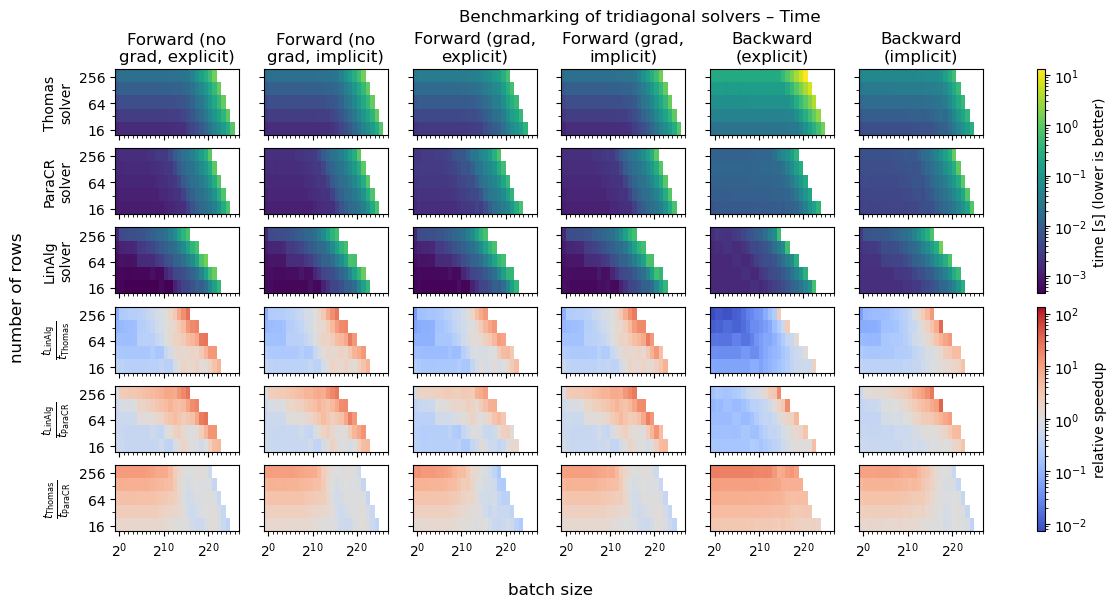

In [ ]:
n_rows_all_edges = [12, 24, 48, 96, 192, 384]
n_batch_all_edges = [2**(i-1.) for i in range(0, 29, 1)]
n_batch_all_edges_long = n_batch_all_edges # [2**(i-1.) for i in range(0, 22, 2)]

fig, ax = plt.subplots(6, 6, sharex=True, sharey=True, figsize=(14, 6))

titles = ["Forward (no\ngrad, explicit)",
         "Forward (no\ngrad, implicit)",
         "Forward (grad,\nexplicit)",
         "Forward (grad,\nimplicit)",
         "Backward\n(explicit)",
         "Backward\n(implicit)"]

arrays_thomas = [t_nograd_ex_thomas, t_nograd_im_thomas, t_grad_ex_thomas, 
                 t_grad_im_thomas, t_back_ex_thomas, t_back_im_thomas]
arrays_paracr = [t_nograd_ex_paracr, t_nograd_im_paracr, t_grad_ex_paracr, 
                 t_grad_im_paracr, t_back_ex_paracr, t_back_im_paracr]
arrays_linalg = [t_nograd_ex_linalg, t_nograd_im_linalg, t_grad_ex_linalg, 
                 t_grad_im_linalg, t_back_ex_linalg, t_back_im_linalg]
arrays_diff_t = [al/at for at, al in zip(arrays_thomas, arrays_linalg)]
arrays_diff_p = [al/ac for ac, al in zip(arrays_paracr, arrays_linalg)]
arrays_diff_pt = [at/ac for ac, at in zip(arrays_paracr, arrays_thomas)]

all_arrays = arrays_thomas + arrays_paracr + arrays_linalg
print(*(torch.min(arr.nan_to_num(torch.inf)) for arr in all_arrays))
global_min = max(min(torch.min(arr[arr>0]) for arr in all_arrays), 0.0000001)
global_max = max(torch.max(arr.nan_to_num(-torch.inf)) for arr in all_arrays)
norm = LogNorm(vmin=global_min, vmax=global_max)
cmap = plt.cm.viridis.copy()
cmap.set_under('black')
print(global_min, global_max)

all_diff = arrays_diff_t + arrays_diff_p + arrays_diff_pt  # these must be ratios > 0
diff_min = min(float(torch.min(arr.nan_to_num(torch.inf))) for arr in all_diff)
diff_max = max(float(torch.max(arr.nan_to_num(-torch.inf))) for arr in all_diff)
# Log-symmetric limits around 1
m = max(diff_max, 1.0 / diff_min)
vmin = 1.0 / m
vmax = m
norm_diff = LogNorm(vmin=vmin, vmax=vmax)

for ax_thomas, ax_paracr, ax_linalg, ax_diff_t, ax_diff_p, ax_diff_pt, title, arr_thomas, arr_paracr, arr_linalg, arr_diff_t, arr_diff_p, arr_diff_pt in zip(
        *ax, titles, arrays_thomas, arrays_paracr, arrays_linalg, arrays_diff_t, arrays_diff_p, arrays_diff_pt):

    ax_thomas.set_title(title)

    ax_thomas.set_xscale('log')
    ax_thomas.set_yscale('log')

    c_t = ax_thomas.pcolormesh(n_batch_all_edges_long if arr_thomas.shape[1]>7 else n_batch_all_edges, n_rows_all_edges, arr_thomas, cmap=cmap, norm=norm)
    c_p = ax_paracr.pcolormesh(n_batch_all_edges, n_rows_all_edges, torch.where(arr_paracr <= 0, 0.1*global_min, arr_paracr), cmap=cmap, norm=norm)
    c_l = ax_linalg.pcolormesh(n_batch_all_edges, n_rows_all_edges, torch.where(arr_linalg <= 0, 0.1*global_min, arr_linalg), cmap=cmap, norm=norm)
    c_dt = ax_diff_t.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_t, norm=norm_diff, cmap="coolwarm")
    c_dp = ax_diff_p.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_p, norm=norm_diff, cmap="coolwarm")
    c_dpt = ax_diff_pt.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_pt, norm=norm_diff, cmap="coolwarm")

    ax_diff_t.set_xticks(n_batch_all, [], minor=True)
    ax_diff_t.set_xticks(n_batch_all[::10], [f'$2^{{{i}}}$' for i in range(0, 28, 1)][::10])#, rotation=90)

    ax_paracr.set_yticks(n_rows_all, [], minor=True)
    ax_paracr.set_yticks(n_rows_all[::2], n_rows_all[::2])

ax[0, 0].set_ylabel("Thomas\nsolver")
ax[1, 0].set_ylabel("ParaCR\nsolver")
ax[2, 0].set_ylabel("LinAlg\nsolver")
ax[3, 0].set_ylabel("$\\frac{t_{\\text{LinAlg}}}{t_{\\text{Thomas}}}$", fontsize='large')
ax[4, 0].set_ylabel("$\\frac{t_{\\text{LinAlg}}}{t_{\\text{ParaCR}}}$", fontsize='large')
ax[5, 0].set_ylabel("$\\frac{t_{\\text{Thomas}}}{t_{\\text{ParaCR}}}$", fontsize='large')

fig.colorbar(c_t, ax=ax[:3].ravel().tolist(), aspect=30, label="time [s] (lower is better)")
fig.colorbar(c_dt, ax=ax[3:].ravel().tolist(), aspect=30, label="relative speedup")

fig.supxlabel("batch size                                  ", y=-0.)
fig.supylabel("number of rows", x=0.05)
fig.suptitle("Benchmarking of tridiagonal solvers – Time")
plt.show()

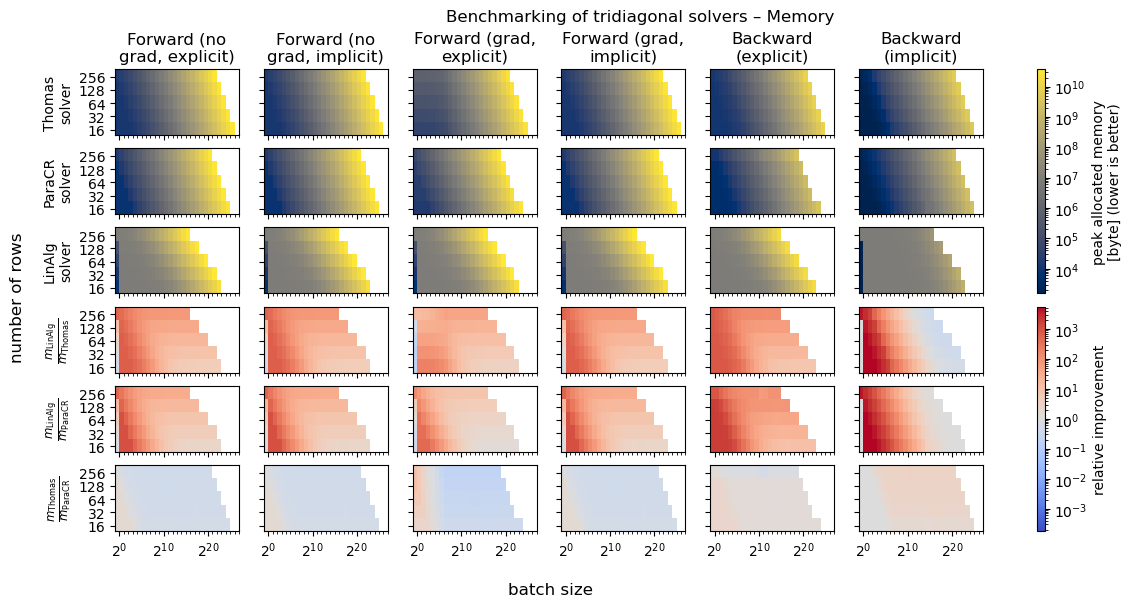

In [ ]:
fig, ax = plt.subplots(6, 6, sharex=True, sharey=True, figsize=(14, 6))

titles = ["Forward (no\ngrad, explicit)",
         "Forward (no\ngrad, implicit)",
         "Forward (grad,\nexplicit)",
         "Forward (grad,\nimplicit)",
         "Backward\n(explicit)",
         "Backward\n(implicit)"]

arrays_thomas = [m_nograd_ex_thomas, m_nograd_im_thomas, m_grad_ex_thomas, 
                 m_grad_im_thomas, m_back_ex_thomas, m_back_im_thomas]
arrays_paracr = [m_nograd_ex_paracr, m_nograd_im_paracr, m_grad_ex_paracr, 
                 m_grad_im_paracr, m_back_ex_paracr, m_back_im_paracr]
arrays_linalg = [m_nograd_ex_linalg, m_nograd_im_linalg, m_grad_ex_linalg, 
                 m_grad_im_linalg, m_back_ex_linalg, m_back_im_linalg]
arrays_diff_t = [al/at for at, al in zip(arrays_thomas, arrays_linalg)]
arrays_diff_p = [al/ac for ac, al in zip(arrays_paracr, arrays_linalg)]
arrays_diff_pt = [at/ac for ac, at in zip(arrays_paracr, arrays_thomas)]

all_arrays = arrays_thomas + arrays_paracr + arrays_linalg
global_min = min(torch.min(arr.nan_to_num(torch.inf)) for arr in all_arrays)
global_max = max(torch.max(arr.nan_to_num(-torch.inf)) for arr in all_arrays)
norm = LogNorm(vmin=global_min, vmax=global_max)

#global_diff_min = min(torch.min(arr) for arr in arrays_diff)
#global_diff_max = max(torch.max(arr) for arr in arrays_diff)
#print(global_diff_min, global_diff_max)
all_diff = arrays_diff_t + arrays_diff_p + arrays_diff_pt  # these must be ratios > 0
diff_min = min(float(torch.min(arr.nan_to_num(torch.inf))) for arr in all_diff)
diff_max = max(float(torch.max(arr.nan_to_num(-torch.inf))) for arr in all_diff)
# Log-symmetric limits around 1
m = max(diff_max, 1.0 / diff_min)
vmin = 1.0 / m
vmax = m
norm_diff = LogNorm(vmin=vmin, vmax=vmax)

for ax_thomas, ax_paracr, ax_linalg, ax_diff_t, ax_diff_p, ax_diff_pt, title, arr_thomas, arr_paracr, arr_linalg, arr_diff_t, arr_diff_p, arr_diff_pt in zip(
        *ax, titles, arrays_thomas, arrays_paracr, arrays_linalg, arrays_diff_t, arrays_diff_p, arrays_diff_pt):

    ax_thomas.set_title(title)

    ax_thomas.set_xscale('log')
    ax_thomas.set_yscale('log')

    c_t = ax_thomas.pcolormesh(n_batch_all_edges_long if arr_thomas.shape[1]>7 else n_batch_all_edges, n_rows_all_edges, arr_thomas, norm=norm, cmap='cividis')
    c_p = ax_paracr.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_paracr, norm=norm, cmap='cividis')
    c_l = ax_linalg.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_linalg, norm=norm, cmap='cividis')
    c_dt = ax_diff_t.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_t, norm=norm_diff, cmap="coolwarm")
    c_dp = ax_diff_p.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_p, norm=norm_diff, cmap="coolwarm")
    c_dpt = ax_diff_pt.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_pt, norm=norm_diff, cmap="coolwarm")

    ax_diff_t.set_xticks(n_batch_all, [], minor=True)
    ax_diff_t.set_xticks(n_batch_all[::10], [f'$2^{{{i}}}$' for i in range(0, 28, 1)][::10])#, rotation=90)

    ax_paracr.set_yticks([], minor=True)
    ax_paracr.set_yticks(n_rows_all, n_rows_all)

ax[0, 0].set_ylabel("Thomas\nsolver")
ax[1, 0].set_ylabel("ParaCR\nsolver")
ax[2, 0].set_ylabel("LinAlg\nsolver")
ax[3, 0].set_ylabel("$\\frac{m_{\\text{LinAlg}}}{m_{\\text{Thomas}}}$", fontsize='large')
ax[4, 0].set_ylabel("$\\frac{m_{\\text{LinAlg}}}{m_{\\text{ParaCR}}}$", fontsize='large')
ax[5, 0].set_ylabel("$\\frac{m_{\\text{Thomas}}}{m_{\\text{ParaCR}}}$", fontsize='large')

fig.colorbar(c_t, ax=ax[:3].ravel().tolist(), aspect=30, label="peak allocated memory\n[byte] (lower is better)")
fig.colorbar(c_dt, ax=ax[3:].ravel().tolist(), aspect=30, label="relative improvement")

fig.supxlabel("batch size                                  ", y=-0.)
fig.supylabel("number of rows", x=0.05)
fig.suptitle("Benchmarking of tridiagonal solvers – Memory")
plt.show()

Text(0.5, 1.0, 'Benchmarking of tridiagonal solvers – Memory')

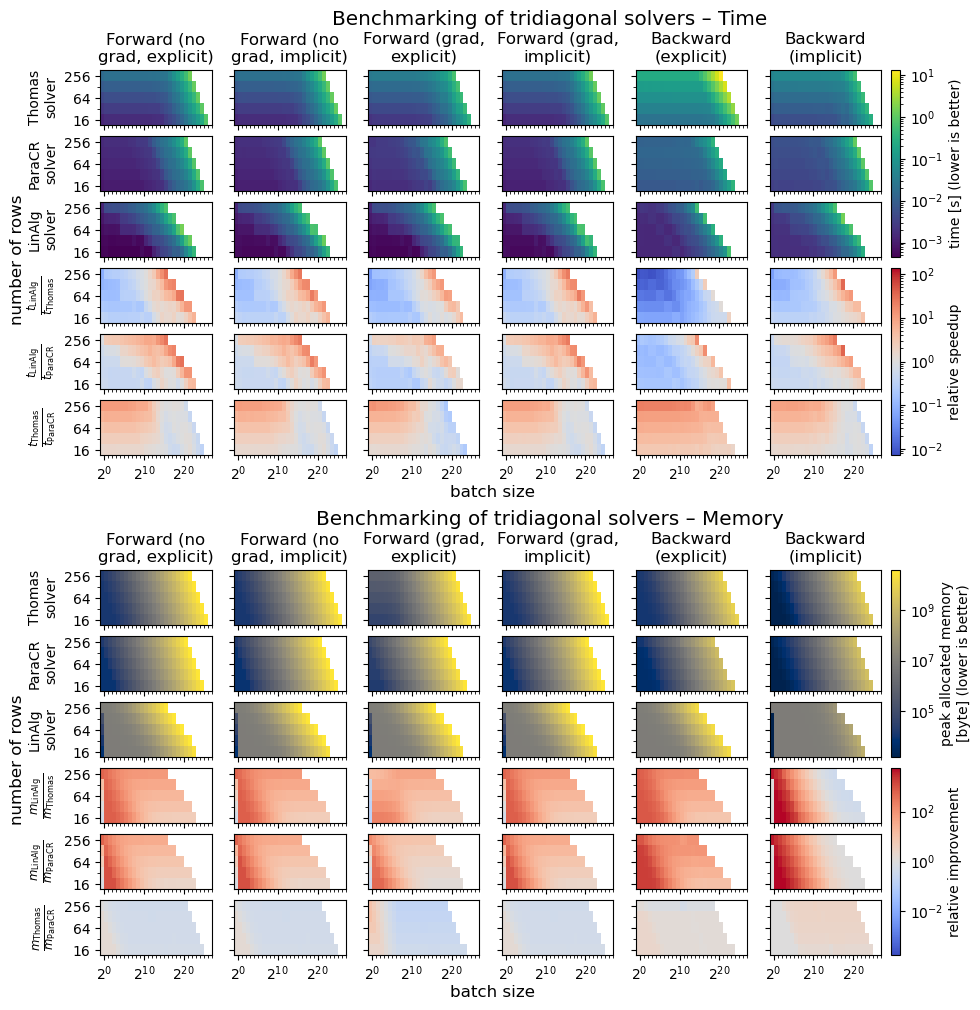

In [ ]:
fig = plt.figure(figsize=(12, 10))

subfig_time, subfig_mem = fig.subfigures(
    2, 1,
    height_ratios=[6, 6]
)

ax_time = subfig_time.subplots(6, 6, sharex=True, sharey=True)
ax_mem  = subfig_mem.subplots(6, 6, sharex=True, sharey=True)



titles = ["Forward (no\ngrad, explicit)",
         "Forward (no\ngrad, implicit)",
         "Forward (grad,\nexplicit)",
         "Forward (grad,\nimplicit)",
         "Backward\n(explicit)",
         "Backward\n(implicit)"]

arrays_thomas = [t_nograd_ex_thomas, t_nograd_im_thomas, t_grad_ex_thomas, 
                 t_grad_im_thomas, t_back_ex_thomas, t_back_im_thomas]
arrays_paracr = [t_nograd_ex_paracr, t_nograd_im_paracr, t_grad_ex_paracr, 
                 t_grad_im_paracr, t_back_ex_paracr, t_back_im_paracr]
arrays_linalg = [t_nograd_ex_linalg, t_nograd_im_linalg, t_grad_ex_linalg, 
                 t_grad_im_linalg, t_back_ex_linalg, t_back_im_linalg]
arrays_diff_t = [al/at for at, al in zip(arrays_thomas, arrays_linalg)]
arrays_diff_p = [al/ac for ac, al in zip(arrays_paracr, arrays_linalg)]
arrays_diff_pt = [at/ac for ac, at in zip(arrays_paracr, arrays_thomas)]

all_arrays = arrays_thomas + arrays_paracr + arrays_linalg
global_min = max(min(torch.min(arr[arr>0]) for arr in all_arrays), 0.0000001)
global_max = max(torch.max(arr.nan_to_num(-torch.inf)) for arr in all_arrays)
norm = LogNorm(vmin=global_min, vmax=global_max)
cmap = plt.cm.viridis.copy()
cmap.set_under('black')

all_diff = arrays_diff_t + arrays_diff_p + arrays_diff_pt  # these must be ratios > 0
diff_min = min(float(torch.min(arr.nan_to_num(torch.inf))) for arr in all_diff)
diff_max = max(float(torch.max(arr.nan_to_num(-torch.inf))) for arr in all_diff)
# Log-symmetric limits around 1
m = max(diff_max, 1.0 / diff_min)
vmin = 1.0 / m
vmax = m
norm_diff = LogNorm(vmin=vmin, vmax=vmax)

for ax_thomas, ax_paracr, ax_linalg, ax_diff_t, ax_diff_p, ax_diff_pt, title, arr_thomas, arr_paracr, arr_linalg, arr_diff_t, arr_diff_p, arr_diff_pt in zip(
# for ax_thomas, ax_paracr, ax_linalg, ax_diff, title, arr_thomas, arr_paracr, arr_linalg in zip(
        *ax_time, titles, arrays_thomas, arrays_paracr, arrays_linalg, arrays_diff_t, arrays_diff_p, arrays_diff_pt):

    ax_thomas.set_title(title)

    ax_thomas.set_xscale('log')
    ax_thomas.set_yscale('log')

    c_t = ax_thomas.pcolormesh(n_batch_all_edges_long if arr_thomas.shape[1]>7 else n_batch_all_edges, n_rows_all_edges, arr_thomas, cmap=cmap, norm=norm)
    c_p = ax_paracr.pcolormesh(n_batch_all_edges, n_rows_all_edges, torch.where(arr_paracr <= 0, 0.1*global_min, arr_paracr), cmap=cmap, norm=norm)
    c_l = ax_linalg.pcolormesh(n_batch_all_edges, n_rows_all_edges, torch.where(arr_linalg <= 0, 0.1*global_min, arr_linalg), cmap=cmap, norm=norm)
    c_dt = ax_diff_t.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_t, norm=norm_diff, cmap="coolwarm")
    c_dp = ax_diff_p.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_p, norm=norm_diff, cmap="coolwarm")
    c_dpt = ax_diff_pt.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_pt, norm=norm_diff, cmap="coolwarm")

    ax_diff_t.set_xticks(n_batch_all, [], minor=True)
    ax_diff_t.set_xticks(n_batch_all[::10], [f'$2^{{{i}}}$' for i in range(0, 28, 1)][::10])#, rotation=90)

    ax_paracr.set_yticks(n_rows_all, [], minor=True)
    ax_paracr.set_yticks(n_rows_all[::2], n_rows_all[::2])

ax_time[0, 0].set_ylabel("Thomas\nsolver")
ax_time[1, 0].set_ylabel("ParaCR\nsolver")
ax_time[2, 0].set_ylabel("LinAlg\nsolver")
ax_time[3, 0].set_ylabel("$\\frac{t_{\\text{LinAlg}}}{t_{\\text{Thomas}}}$", fontsize='large')
ax_time[4, 0].set_ylabel("$\\frac{t_{\\text{LinAlg}}}{t_{\\text{ParaCR}}}$", fontsize='large')
ax_time[5, 0].set_ylabel("$\\frac{t_{\\text{Thomas}}}{t_{\\text{ParaCR}}}$", fontsize='large')

subfig_time.colorbar(c_t, ax=ax_time[:3].ravel().tolist(), aspect=20, pad=0.01, label="time [s] (lower is better)")
subfig_time.colorbar(c_dt, ax=ax_time[3:].ravel().tolist(), aspect=20, pad=0.01, label="relative speedup")

subfig_time.supxlabel("batch size                      ", y=0.02)
subfig_time.supylabel("number of rows", x=0.05)

subfig_time.suptitle("Benchmarking of tridiagonal solvers – Time", y=1., fontsize='x-large')





arrays_thomas = [m_nograd_ex_thomas, m_nograd_im_thomas, m_grad_ex_thomas, 
                 m_grad_im_thomas, m_back_ex_thomas, m_back_im_thomas]
arrays_paracr = [m_nograd_ex_paracr, m_nograd_im_paracr, m_grad_ex_paracr, 
                 m_grad_im_paracr, m_back_ex_paracr, m_back_im_paracr]
arrays_linalg = [m_nograd_ex_linalg, m_nograd_im_linalg, m_grad_ex_linalg, 
                 m_grad_im_linalg, m_back_ex_linalg, m_back_im_linalg]
arrays_diff_t = [al/at for at, al in zip(arrays_thomas, arrays_linalg)]
arrays_diff_p = [al/ac for ac, al in zip(arrays_paracr, arrays_linalg)]
arrays_diff_pt = [at/ac for ac, at in zip(arrays_paracr, arrays_thomas)]

all_arrays = arrays_thomas + arrays_paracr + arrays_linalg
global_min = min(torch.min(arr.nan_to_num(torch.inf)) for arr in all_arrays)
global_max = max(torch.max(arr.nan_to_num(-torch.inf)) for arr in all_arrays)
norm = LogNorm(vmin=global_min, vmax=global_max)

all_diff = arrays_diff_t + arrays_diff_p + arrays_diff_pt  # these must be ratios > 0
diff_min = min(float(torch.min(arr.nan_to_num(torch.inf))) for arr in all_diff)
diff_max = max(float(torch.max(arr.nan_to_num(-torch.inf))) for arr in all_diff)
# Log-symmetric limits around 1
m = max(diff_max, 1.0 / diff_min)
vmin = 1.0 / m
vmax = m
norm_diff = LogNorm(vmin=vmin, vmax=vmax)

for ax_thomas, ax_paracr, ax_linalg, ax_diff_t, ax_diff_p, ax_diff_pt, title, arr_thomas, arr_paracr, arr_linalg, arr_diff_t, arr_diff_p, arr_diff_pt in zip(
        *ax_mem, titles, arrays_thomas, arrays_paracr, arrays_linalg, arrays_diff_t, arrays_diff_p, arrays_diff_pt):

    ax_thomas.set_title(title)

    ax_thomas.set_xscale('log')
    ax_thomas.set_yscale('log')

    c_t = ax_thomas.pcolormesh(n_batch_all_edges_long if arr_thomas.shape[1]>7 else n_batch_all_edges, n_rows_all_edges, arr_thomas, norm=norm, cmap='cividis')
    c_p = ax_paracr.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_paracr, norm=norm, cmap='cividis')
    c_l = ax_linalg.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_linalg, norm=norm, cmap='cividis')
    c_dt = ax_diff_t.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_t, norm=norm_diff, cmap="coolwarm")
    c_dp = ax_diff_p.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_p, norm=norm_diff, cmap="coolwarm")
    c_dpt = ax_diff_pt.pcolormesh(n_batch_all_edges, n_rows_all_edges, arr_diff_pt, norm=norm_diff, cmap="coolwarm")

    ax_diff_t.set_xticks(n_batch_all, [], minor=True)
    ax_diff_t.set_xticks(n_batch_all[::10], [f'$2^{{{i}}}$' for i in range(0, 28, 1)][::10])#, rotation=90)

    ax_paracr.set_yticks(n_rows_all, [], minor=True)
    ax_paracr.set_yticks(n_rows_all[::2], n_rows_all[::2])

ax_mem[0, 0].set_ylabel("Thomas\nsolver")
ax_mem[1, 0].set_ylabel("ParaCR\nsolver")
ax_mem[2, 0].set_ylabel("LinAlg\nsolver")
ax_mem[3, 0].set_ylabel("$\\frac{m_{\\text{LinAlg}}}{m_{\\text{Thomas}}}$", fontsize='large')
ax_mem[4, 0].set_ylabel("$\\frac{m_{\\text{LinAlg}}}{m_{\\text{ParaCR}}}$", fontsize='large')
ax_mem[5, 0].set_ylabel("$\\frac{m_{\\text{Thomas}}}{m_{\\text{ParaCR}}}$", fontsize='large')

subfig_mem.colorbar(c_t, ax=ax_mem[:3].ravel().tolist(), aspect=20, pad=0.01, label="peak allocated memory\n[byte] (lower is better)")
subfig_mem.colorbar(c_dt, ax=ax_mem[3:].ravel().tolist(), aspect=20, pad=0.01, label="relative improvement")

subfig_mem.supxlabel("batch size                      ", y=0.02)
subfig_mem.supylabel("number of rows", x=0.05)

subfig_mem.suptitle("Benchmarking of tridiagonal solvers – Memory", y=1., fontsize='x-large')

# Evaluate scaling behavior

In [ ]:
n_batch_test = [int(2**(i/2)) for i in range(0, 23*2, 1)]

0.0005619673986022311 1.0482656435393113e-07


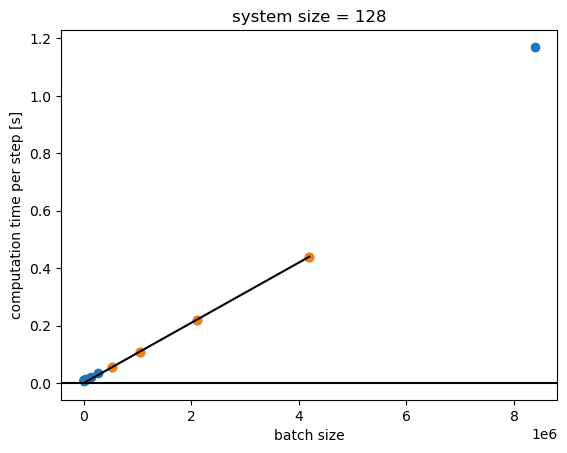

In [ ]:
i_n = 3
plt.scatter(n_batch_all, t_nograd_ex_thomas[i_n])
_x, _y = n_batch_all[-9:-5], t_nograd_ex_thomas[i_n][-9:-5]
plt.scatter(_x, _y)
_b, _m = np.polynomial.polynomial.polyfit(_x, _y, 1)
print(_b, _m)
plt.plot(np.linspace(0, _x[-1], 100), np.linspace(0, _x[-1], 100) * _m + _b, c='black')
plt.axhline(_b, c='black')
plt.xlabel('batch size'); plt.ylabel('computation time per step [s]'); plt.title(f'system size = {n_rows_all[i_n]}'); plt.show()